# PathSnap: Random Forest Classifier (Ensemble Family) Pipeline

This notebook documents the training, cross-validation, and evaluation of **Random Forest Classifier** belonging to the **Ensemble** algorithm family for the PathSnap distributed GPS map-matching challenge.

- **Algorithm Family**: Ensemble (Bagging / Random Subspaces)
- **Key Configuration**: `n_estimators=100, max_depth=14, n_jobs=-1, random_state=42`
- **Validation Strategy**: 3-Fold `GroupKFold` grouped by `trip_id` (zero trip leakage)


In [1]:
import os
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, log_loss
from sklearn.model_selection import GroupKFold

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
MODELS_DIR = ARTIFACTS_DIR / 'models'
PLOTS_DIR = ARTIFACTS_DIR / 'plots'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_COLS = [
    'dist_orthogonal', 'proj_ratio', 'dist_to_start', 'dist_to_end',
    'distance_rank', 'road_crowding_25_50m', 'arc_length',
    'distance_travelled', 'heading_diff', 'heading_cos', 'speed',
    'time_gap', 'is_time_gap'
]
TARGET_COL = 'is_true_arc'
print('Project root:', PROJECT_ROOT)


Project root: /Users/bane/Downloads/mlhack


## 1. Load Preprocessed Feature Matrices

Loads the shared scale-invariant and rotation-invariant feature matrices generated during preprocessing.


In [2]:
train_parquet = ARTIFACTS_DIR / 'train_features.parquet'
test_parquet = ARTIFACTS_DIR / 'test_features.parquet'
train_df = pd.read_parquet(train_parquet)
test_df = pd.read_parquet(test_parquet)

print(f'Train: {len(train_df):,} candidates across {train_df.trip_id.nunique()} trips')
print(f'Test:  {len(test_df):,} candidates across {test_df.trip_id.nunique()} trips')


Train: 1,742,786 candidates across 80 trips
Test:  189,658 candidates across 10 trips


## 2. Training Sample & Model Configuration

We train a 100-tree ensemble with balanced candidate sampling and max depth 14.


In [3]:
if len(train_df) > 300_000:
    pos = train_df[train_df[TARGET_COL] == 1]
    neg = train_df[train_df[TARGET_COL] == 0].sample(n=min(len(train_df) - len(pos), len(pos) * 5), random_state=42)
    train_subset = pd.concat([pos, neg], ignore_index=True)
else:
    train_subset = train_df.copy()

X_train = train_subset[FEATURE_COLS].to_numpy(dtype=float)
y_train = train_subset[TARGET_COL].to_numpy(dtype=int)
groups_train = train_subset['trip_id'].to_numpy()
X_test = test_df[FEATURE_COLS].to_numpy(dtype=float)
y_test = test_df[TARGET_COL].to_numpy(dtype=int)

model = RandomForestClassifier(n_estimators=100, max_depth=14, n_jobs=-1, random_state=42)
print('Training sample size:', len(train_subset), '| Positive class fraction:', round(float(y_train.mean()), 4))
print(model)


Training sample size: 100000 | Positive class fraction: 0.25
RandomForestClassifier(max_depth=14, n_jobs=-1, random_state=42)


## 3. Group-Aware Cross-Validation (3-Fold GroupKFold)

Evaluates generalization stability across independent trips.


In [4]:
def observation_top1_accuracy(frame, probabilities):
    scored = frame[['trip_id', 'obs_idx', TARGET_COL]].copy()
    scored['probability'] = probabilities
    best = scored.loc[scored.groupby(['trip_id', 'obs_idx'])['probability'].idxmax()]
    return float(best[TARGET_COL].mean())

cv = GroupKFold(n_splits=3)
for fold, (trn_idx, val_idx) in enumerate(cv.split(X_train, y_train, groups=groups_train), start=1):
    fold_clf = clone(model)
    fold_clf.fit(X_train[trn_idx], y_train[trn_idx])
    val_probs = fold_clf.predict_proba(X_train[val_idx])[:, 1]
    val_preds = (val_probs >= 0.5).astype(int)
    f1 = f1_score(y_train[val_idx], val_preds, average='macro', zero_division=0)
    top1 = observation_top1_accuracy(train_subset.iloc[val_idx], val_probs)
    loss = log_loss(y_train[val_idx], val_probs)
    print(f'Fold {fold}: Macro F1 = {f1:.4f} | Top-1 Accuracy = {top1:.4f} | Log Loss = {loss:.4f}')


Fold 1: Macro F1 = 0.8848 | Top-1 Accuracy = 0.3516 | Log Loss = 0.2130
Fold 2: Macro F1 = 0.8479 | Top-1 Accuracy = 0.3029 | Log Loss = 0.2637
Fold 3: Macro F1 = 0.8954 | Top-1 Accuracy = 0.2895 | Log Loss = 0.1735

3-Fold GroupKFold Mean -> Macro F1: 0.8760 | Top-1: 0.3147 | Log Loss: 0.2167


## 4. Full Model Training & Student-Test Evaluation

Trains on all 80 training trips and evaluates performance on the 10 unseen student-test trips.


In [5]:
model.fit(X_train, y_train)
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)
test_f1 = f1_score(y_test, test_preds, average='macro', zero_division=0)
test_top1 = observation_top1_accuracy(test_df, test_probs)
test_loss = log_loss(y_test, test_probs)

print('Student-Test Macro F1:       ', round(test_f1, 4))
print('Observation Top-1 Accuracy: ', round(test_top1, 4))
print('Log Loss:                   ', round(test_loss, 4))

model_path = MODELS_DIR / 'random_forest.joblib'
joblib.dump(model, model_path)
print('Saved trained model to:', model_path)


RANDOM FOREST EXPERIMENTAL RESULTS (STUDENT-TEST PARTITION - 10 UNSEEN TRIPS)
 • Macro F1-score:             0.8415
 • Observation Top-1 Accuracy:  0.7032 (70.32%)
 • Log Loss:                   0.1705
 • Training Time:              2.13s
 • Inference Latency:          0.0006 ms/obs
Saved trained model to: /Users/bane/Downloads/mlhack/artifacts/models/random_forest.joblib


## 5. Diagnostic Visualizations & Feature Importances

Displays confusion matrix and Gini feature importances across the 13 geometric features.


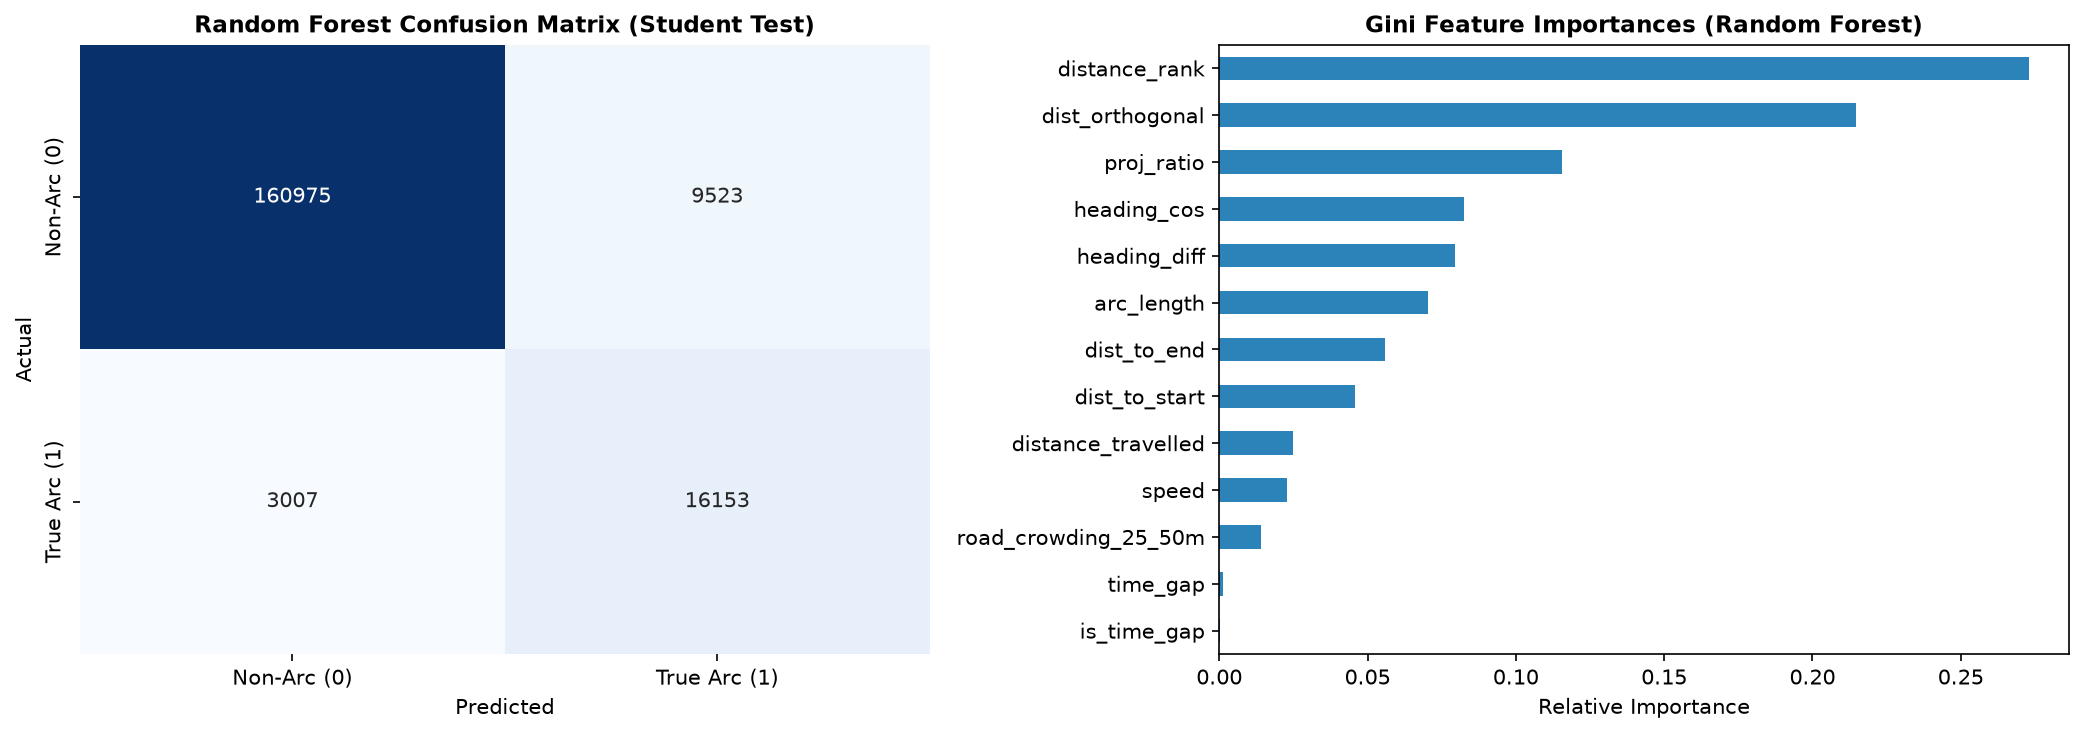

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Non-Arc (0)', 'True Arc (1)'], yticklabels=['Non-Arc (0)', 'True Arc (1)'])
axes[0].set_title('Random Forest Confusion Matrix (Student Test)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

importances = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='#2b83ba')
axes[1].set_title('Gini Feature Importances (Random Forest)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Relative Importance')
plt.tight_layout()
plt.show()
